In [2]:
import os
import pickle
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon
import matplotlib.pyplot as plt


# Plottig the Nuclei
The first cell plots ALL nuclei that were denoted in the pickle files storing the polygons.

The second cell only plots the nuclei that overlap with barcodes from the Visium HD results. 

Number of nuclei found: 1263888


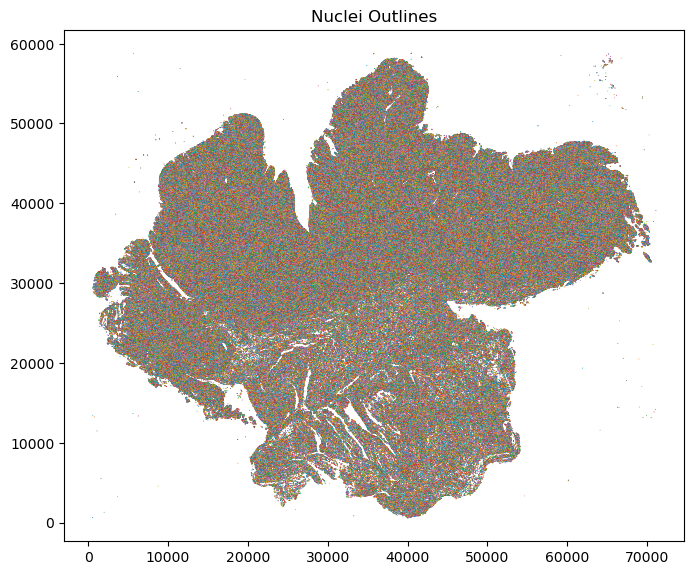

In [ ]:
# Load polys
# Note: curent polys are the ones from NucleiSegmentation.py and the ong image
with open("output_local/output/polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)

print(f"Number of nuclei found: {len(polys['coord'])}")
# Plot outlines
fig, ax = plt.subplots(figsize=(8, 8))
for y_coords, x_coords in polys['coord']:
    ax.plot(x_coords, y_coords, linewidth=0.5)

ax.set_aspect('equal')
ax.set_title("Nuclei Outlines")
plt.show()


100%|██████████| 1263888/1263888 [35:43<00:00, 589.64it/s]


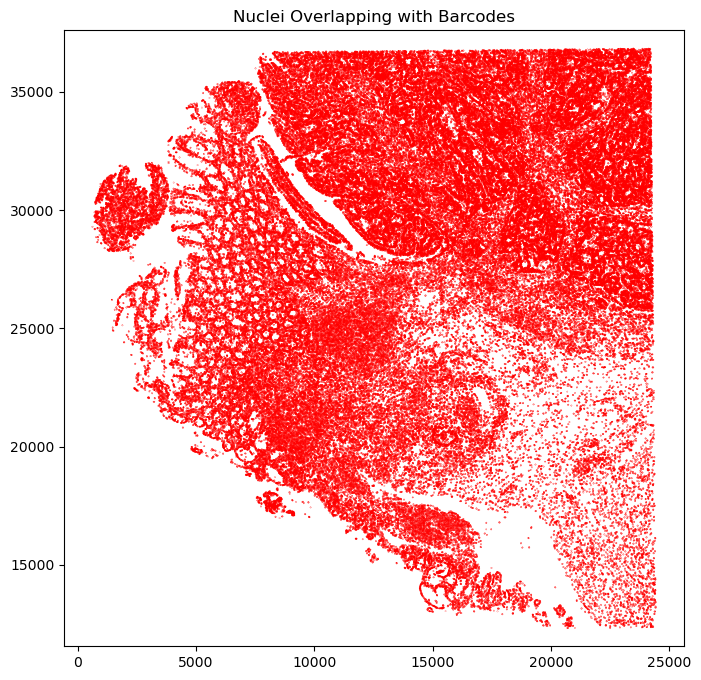

In [4]:
with open("output_local/output/polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)

# Load csv with barcode matches
result_df = pd.read_csv("output_local/output/Nuclei_Barcode_Map.csv")

# Extract overlapping IDs within one or several nuclei polygons
matched_ids = result_df["id"].unique()

from tqdm import tqdm  # optional, for progress bar

# Create all polygons with their IDs
geometries = []
ids = []

for i, (y_coords, x_coords) in enumerate(tqdm(polys['coord'])):
    polygon = Polygon(zip(x_coords, y_coords))
    polygon_id = f"ID_{i+1}"
    
    # TODO: optimise with search tree oder so
    if polygon_id in matched_ids:  # or use 'matched_ids'
        geometries.append(polygon)
        ids.append(polygon_id)

# Build GeoDataFrame
gdf = gpd.GeoDataFrame({"id": ids, "geometry": geometries})

# Plot the nuclei that overlap with barcodes
# Note: Adjust the edgecolor and facecolor as needed
fig, ax = plt.subplots(figsize=(8, 8))
gdf.plot(ax=ax, edgecolor='red', facecolor='none', linewidth=1)
plt.title("Nuclei Overlapping with Barcodes")
plt.axis("equal")
plt.show()

In [6]:
# print the first 5 nuclei coordinates
for i, (y_coords, x_coords) in enumerate(polys['coord'][:5]):
    print(f"Nucleus {i}:")
    print("  y_coords:", y_coords)
    print("  x_coords:", x_coords)

Nucleus 0:
  y_coords: [1688.         1691.26867676 1694.59350586 1697.53857422 1700.51647949
 1702.94970703 1705.01989746 1705.89074707 1707.03637695 1706.12438965
 1705.40344238 1703.84228516 1701.15795898 1698.07568359 1694.6217041
 1691.09094238 1688.         1685.17333984 1682.42041016 1679.79260254
 1677.09936523 1674.66455078 1672.27868652 1671.27233887 1669.97509766
 1670.37866211 1671.11157227 1672.98449707 1675.37365723 1678.21911621
 1681.25       1684.61523438]
  x_coords: [549.125      548.43255615 547.91827393 546.27545166 544.51647949
 541.98907471 539.04986572 535.55871582 532.         528.39483643
 524.79125977 521.41455078 518.84210205 516.9206543  516.01373291
 516.46075439 516.70941162 517.78948975 518.52966309 519.71679688
 521.09936523 523.08953857 525.48797607 528.67266846 532.
 535.50512695 538.99542236 542.03308105 544.62628174 546.63812256
 548.29595947 549.01611328]
Nucleus 1:
  y_coords: [2328.         2330.97827148 2333.81176758 2336.18188477 2338.51171875
